# Studio 2 — Kulkas LG 2 Pintu (Colab)
Fine-tuning ConvNeXt-Tiny pretrained ImageNet. Jalankan sel dari atas ke bawah.

**Sebelum mulai**
1. `Runtime > Change runtime type > T4 GPU`.
2. Buka folder dataset di Drive: https://drive.google.com/drive/folders/1_XcZoDFRznHB7fI603VHzdFxreg3ma60 lalu klik nama folder di atas > **Organize > Add shortcut** > pilih *My Drive*. Kalau folder `train` sudah ada di My Drive Anda, langkah ini tidak perlu. Kalau auto-detect gagal, isi `DATA_DIR` di sel data.
3. Jangan unggah dataset ke Kaggle / HuggingFace / repo publik. Yang di-commit hanya kode + `model.pth`.

**Dua tahap**: tahap 1 `FULL_TRAIN = False` (ada validasi untuk memilih epoch & melihat skor). Tahap 2 (opsional) `FULL_TRAIN = True` untuk melatih ulang di 100% data dengan konfigurasi yang sama.

In [ ]:
import torch
print(torch.__version__, '| CUDA:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Aktifkan GPU: Runtime > Change runtime type > T4 GPU'
!nvidia-smi -L

2.11.0+cu130 | CUDA: True
GPU 0: Tesla T4 (UUID: GPU-f5be037a-376c-724c-2386-a7257365e6a7)


## 1. Konfigurasi

In [ ]:
import os, copy, time, random, shutil, sys, importlib
from pathlib import Path
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix

DRIVE_FOLDER_URL = 'https://drive.google.com/drive/folders/1_XcZoDFRznHB7fI603VHzdFxreg3ma60'
CLASSES = ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']  # urutan kontrak (alfabetis)
NUM_CLASSES = 5
IMG_EXT = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

MODEL_NAME = 'convnext_tiny'   # 'convnext_small' juga bisa, TAPI bobot fp16 ~100MB = mepet batas GitHub 100MB
IMG_SIZE = 224
EPOCHS, BATCH, LR, WD, SMOOTH, VAL_FRAC, SEED = 20, 32, 2e-4, 0.05, 0.1, 0.15, 13
FULL_TRAIN = False             # True = latih di 100% data (val hanya sanity check, skornya BOCOR/tidak bermakna)

OUT = 'submission/model.pth'
BACKUP_DIR = '/content/drive/MyDrive/studio2_out'   # salinan model terbaik, aman kalau sesi Colab putus
os.makedirs('submission', exist_ok=True)

device = torch.device('cuda')
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

## 2. Ambil dataset dari Drive (tanpa mengunggah ulang ke mana pun)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Kalau auto-detect gagal, isi path folder yang berisi kelima folder kelas, mis. '/content/drive/MyDrive/train'
DATA_DIR = ''

def has_classes(d):
    return bool(d) and os.path.isdir(d) and all(os.path.isdir(os.path.join(d, c)) for c in CLASSES)

def find_root(base, max_depth=8):
    if not os.path.isdir(base): return None
    base = base.rstrip('/'); d0 = base.count('/')
    for root, dirs, files in os.walk(base, followlinks=True):
        if root.count('/') - d0 >= max_depth:
            dirs[:] = []; continue
        dirs[:] = [d for d in dirs if not d.startswith('.')]
        if all(c in dirs for c in CLASSES):
            return root
    return None

def find_zip(base, max_depth=4):
    if not os.path.isdir(base): return None
    base = base.rstrip('/'); d0 = base.count('/')
    for root, dirs, files in os.walk(base, followlinks=True):
        if root.count('/') - d0 >= max_depth:
            dirs[:] = []; continue
        dirs[:] = [d for d in dirs if not d.startswith('.')]
        for f in files:
            if f.lower().endswith('.zip') and 'train' in f.lower():
                return os.path.join(root, f)
    return None

def class_counts(root):
    return {c: sum(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(root, c))) for c in CLASSES}

SRC = DATA_DIR if has_classes(DATA_DIR) else None
if DATA_DIR and SRC is None:
    print('DATA_DIR tidak berisi kelima folder kelas. Isinya:', sorted(os.listdir(DATA_DIR))[:30] if os.path.isdir(DATA_DIR) else 'folder tidak ada')
for base in ('/content/drive/MyDrive', '/content/drive/Shareddrives'):
    if SRC is None: SRC = find_root(base)
if SRC is None:
    z = find_zip('/content/drive/MyDrive')
    if z:
        print('unzip', z)
        !unzip -q -o "{z}" -d /content/unzipped
        SRC = find_root('/content/unzipped')

if SRC is None:
    top = sorted(os.listdir('/content/drive/MyDrive'))
    print('Isi /content/drive/MyDrive:', top[:80])
    if 'train' in top:
        print('Isi MyDrive/train:', sorted(os.listdir('/content/drive/MyDrive/train'))[:30])
    raise SystemExit('Folder kelas tidak ditemukan. Isi DATA_DIR dengan path yang benar lalu jalankan ulang sel ini, '
                     'dan kirim output di atas kalau masih gagal.')

counts = class_counts(SRC)
print('SRC =', SRC); print(counts, '| total', sum(counts.values()))
assert sum(counts.values()) >= 2500, 'Jumlah gambar jauh di bawah +-2.900 -> dataset tidak lengkap.'

# salin ke disk lokal supaya baca cepat
TRAIN_DIR = '/content/train_local'
shutil.rmtree(TRAIN_DIR, ignore_errors=True)
for c in CLASSES:
    shutil.copytree(os.path.join(SRC, c), os.path.join(TRAIN_DIR, c))
print('disalin ke', TRAIN_DIR)

Mounted at /content/drive
SRC = /content/drive/MyDrive/train
{'botol_plastik': 523, 'gelas_plastik': 521, 'kertas_kardus': 365, 'saset_kemasan': 673, 'styrofoam': 671} | total 2753
disalin ke /content/train_local


## 3. Muat gambar, dedup per kelas, split, simpan `my_val/`

In [ ]:
def shrink(im, s=256):
    im = im.convert('RGB'); w, h = im.size; r = s / min(w, h)
    return im.resize((max(s, round(w * r)), max(s, round(h * r))), Image.BILINEAR)

images, labels, paths = [], [], []
for ci, c in enumerate(CLASSES):
    for p in sorted(Path(TRAIN_DIR, c).iterdir()):
        if p.suffix.lower() in IMG_EXT:
            try:
                images.append(shrink(Image.open(p))); labels.append(ci); paths.append(str(p))
            except Exception as e:
                print('skip', p.name, e)
labels = np.array(labels)
print(len(images), np.bincount(labels, minlength=NUM_CLASSES))

# dedup eksak per kelas (dHash 16x16 = 256 bit; hanya duplikat nyaris identik yang terbuang)
def dhash(im, n=16):
    a = np.asarray(im.convert('L').resize((n + 1, n), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).tobytes()
seen, keep = set(), []
for i, im in enumerate(images):
    k = (int(labels[i]), dhash(im))
    if k not in seen:
        seen.add(k); keep.append(i)
print('duplikat dibuang:', len(images) - len(keep))
images = [images[i] for i in keep]; labels = labels[keep]; paths = [paths[i] for i in keep]

idx = np.arange(len(images))
if FULL_TRAIN:
    tr_idx, va_idx = idx, idx[:200]
else:
    tr_idx, va_idx = train_test_split(idx, test_size=VAL_FRAC, stratify=labels, random_state=SEED)

shutil.rmtree('my_val', ignore_errors=True)
for i in va_idx:
    d = Path('my_val') / CLASSES[labels[i]]; d.mkdir(parents=True, exist_ok=True)
    images[i].save(d / f'{i}.png')
print(f'train {len(tr_idx)} | val {len(va_idx)}')

2753 [523 521 365 673 671]
duplikat dibuang: 0
train 2340 | val 413


## 4. Tulis `submission/model.py` dulu, lalu pakai kode yang SAMA untuk training (tidak ada selisih arsitektur)

In [ ]:
MODEL_PY = '''import torch
import torch.nn as nn
from torchvision import models, transforms

NUM_CLASSES, IMG_SIZE = 5, __IMG_SIZE__
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = models.__MODEL_NAME__(weights=None)
        self.net.classifier[2] = nn.Linear(768, NUM_CLASSES)

    def forward(self, x):
        out = self.net(x)
        if not self.training:  # TTA: rata-rata logits gambar asli + flip horizontal
            out = (out + self.net(torch.flip(x, dims=[3]))) / 2
        return out


def get_model():
    # arsitektur saja: tanpa mengunduh bobot / memuat model.pth
    return Net()


def get_transform():
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
'''.replace('__IMG_SIZE__', str(IMG_SIZE)).replace('__MODEL_NAME__', MODEL_NAME)
open('submission/model.py', 'w').write(MODEL_PY)
open('submission/requirements.txt', 'w').write('')   # hanya torch/torchvision/pillow/numpy -> sudah tersedia

sys.path.insert(0, os.getcwd())
import submission.model as sm
importlib.reload(sm)
MEAN, STD = sm.MEAN, sm.STD

val_tf = sm.get_transform()
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])

model = sm.get_model()
wcls = {'convnext_tiny': models.ConvNeXt_Tiny_Weights, 'convnext_small': models.ConvNeXt_Small_Weights}[MODEL_NAME]
w = wcls.DEFAULT.get_state_dict(progress=True)
w = {k: v for k, v in w.items() if not k.startswith('classifier.2')}
print(model.net.load_state_dict(w, strict=False))   # harus: hanya classifier.2.* yang missing
model.to(device)
print('params:', sum(p.numel() for p in model.parameters()) / 1e6, 'M')

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 301MB/s] 


_IncompatibleKeys(missing_keys=['classifier.2.weight', 'classifier.2.bias'], unexpected_keys=[])
params: 27.823973 M


## 5. DataLoader

In [ ]:
class DS(Dataset):
    def __init__(s, ids, tf): s.ids, s.tf = ids, tf
    def __len__(s): return len(s.ids)
    def __getitem__(s, k):
        i = s.ids[k]; return s.tf(images[i]), int(labels[i])

cnt = np.bincount(labels[tr_idx], minlength=NUM_CLASSES)
sw = (1.0 / np.sqrt(cnt))[labels[tr_idx]]          # penyeimbang ringan antar kelas
sampler = torch.utils.data.WeightedRandomSampler(sw, len(tr_idx), replacement=True)
W = min(4, os.cpu_count() or 2)
tl = DataLoader(DS(tr_idx, train_tf), BATCH, sampler=sampler, num_workers=W, drop_last=True, pin_memory=True)
vl = DataLoader(DS(va_idx, val_tf), 64, shuffle=False, num_workers=W)
print('steps/epoch:', len(tl), '| workers:', W)

steps/epoch: 73 | workers: 2


## 6. Training (AdamW + warmup + cosine, AMP, label smoothing). Model terbaik (Macro-F1 val) disimpan fp16

In [ ]:
def save_fp16(m, path):
    torch.save({k: (v.half() if v.is_floating_point() else v) for k, v in m.state_dict().items()}, path)

def evaluate(m):
    m.eval(); P, T = [], []
    with torch.no_grad():
        for x, y in vl:
            P += m(x.to(device)).argmax(1).cpu().tolist(); T += y.tolist()
    return np.array(P), np.array(T)

crit = nn.CrossEntropyLoss(label_smoothing=SMOOTH)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
steps, warm = EPOCHS * len(tl), len(tl)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, steps - warm))))
scaler = torch.amp.GradScaler('cuda')
os.makedirs(BACKUP_DIR, exist_ok=True)

best_f1, best_ep, hist = -1, 0, []
for ep in range(EPOCHS):
    t0 = time.time(); model.train(); tot = 0
    for x, y in tl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda'):
            loss = crit(model(x), y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
    P, T = evaluate(model)
    f1 = f1_score(T, P, average='macro'); hist.append(f1)
    if f1 >= best_f1 or FULL_TRAIN:          # FULL_TRAIN: simpan epoch terakhir (val bocor, tak bisa dipakai memilih)
        best_f1, best_ep = f1, ep + 1
        save_fp16(model, OUT)
        try: shutil.copy(OUT, os.path.join(BACKUP_DIR, 'model.pth'))
        except Exception as e: print('backup gagal:', e)
    print(f'ep {ep+1}/{EPOCHS} loss {tot/len(tl):.4f} valF1 {f1:.4f} best {best_f1:.4f}@{best_ep} {time.time()-t0:.0f}s')

ep 1/20 loss 1.0357 valF1 0.9216 best 0.9216@1 33s
ep 2/20 loss 0.5969 valF1 0.9508 best 0.9508@2 26s
ep 3/20 loss 0.5378 valF1 0.9467 best 0.9508@2 26s
ep 4/20 loss 0.5113 valF1 0.9542 best 0.9542@4 26s
ep 5/20 loss 0.4932 valF1 0.9642 best 0.9642@5 26s
ep 6/20 loss 0.4845 valF1 0.9418 best 0.9642@5 26s
ep 7/20 loss 0.4889 valF1 0.9257 best 0.9642@5 25s
ep 8/20 loss 0.4663 valF1 0.9544 best 0.9642@5 24s
ep 9/20 loss 0.4472 valF1 0.9584 best 0.9642@5 25s
ep 10/20 loss 0.4438 valF1 0.9619 best 0.9642@5 25s
ep 11/20 loss 0.4441 valF1 0.9709 best 0.9709@11 25s
ep 12/20 loss 0.4389 valF1 0.9740 best 0.9740@12 27s
ep 13/20 loss 0.4256 valF1 0.9660 best 0.9740@12 26s
ep 14/20 loss 0.4278 valF1 0.9687 best 0.9740@12 25s
ep 15/20 loss 0.4189 valF1 0.9720 best 0.9740@12 25s
ep 16/20 loss 0.4241 valF1 0.9689 best 0.9740@12 25s
ep 17/20 loss 0.4171 valF1 0.9720 best 0.9740@12 24s
ep 18/20 loss 0.4066 valF1 0.9700 best 0.9740@12 25s
ep 19/20 loss 0.4081 valF1 0.9697 best 0.9740@12 25s
ep 20/20 los

## 7. Laporan + gambar yang salah prediksi (cek label noise)

               precision    recall  f1-score   support

botol_plastik     0.9872    0.9872    0.9872        78
gelas_plastik     0.9625    0.9872    0.9747        78
kertas_kardus     0.9483    1.0000    0.9735        55
saset_kemasan     0.9794    0.9406    0.9596       101
    styrofoam     0.9800    0.9703    0.9751       101

     accuracy                         0.9734       413
    macro avg     0.9715    0.9771    0.9740       413
 weighted avg     0.9737    0.9734    0.9733       413

[[77  1  0  0  0]
 [ 0 77  1  0  0]
 [ 0  0 55  0  0]
 [ 1  1  2 95  2]
 [ 0  1  0  2 98]]
salah: 11 dari 413


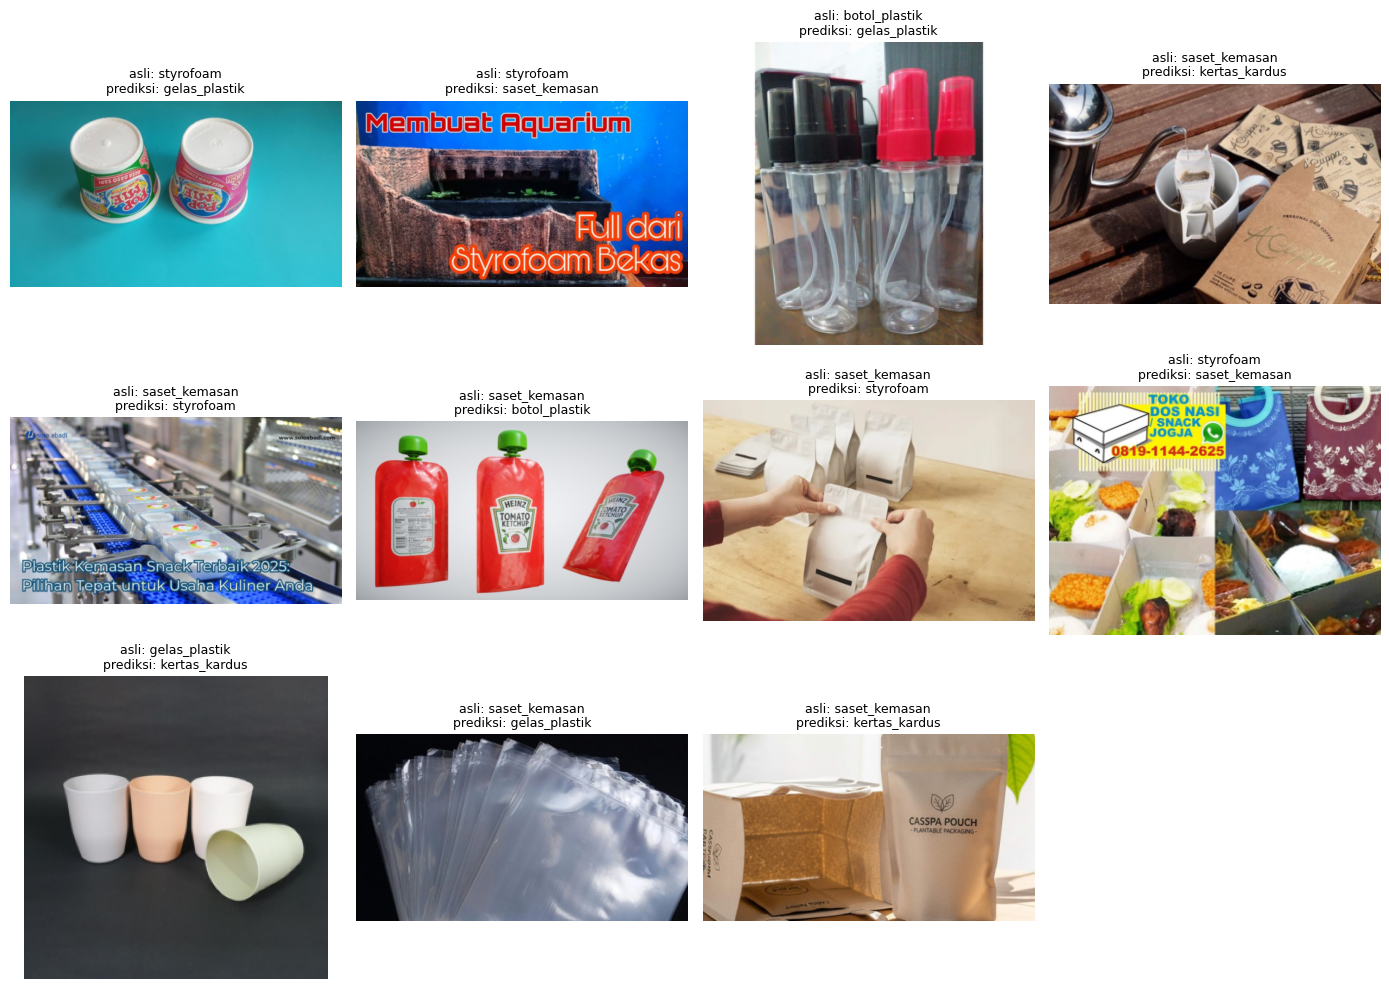

In [ ]:
sd = torch.load(OUT, map_location=device)
model.load_state_dict(sd); P, T = evaluate(model)
print(classification_report(T, P, target_names=CLASSES, digits=4))
print(confusion_matrix(T, P))

wrong = np.where(P != T)[0]
print('salah:', len(wrong), 'dari', len(T))
show = wrong[:12]
if len(show):
    fig, ax = plt.subplots(3, 4, figsize=(14, 10))
    for a in ax.ravel(): a.axis('off')
    for a, k in zip(ax.ravel(), show):
        a.imshow(images[va_idx[k]])
        a.set_title(f'asli: {CLASSES[T[k]]}\nprediksi: {CLASSES[P[k]]}', fontsize=9)
    plt.tight_layout(); plt.show()

## 8. Uji dengan evaluate.py RESMI (starter kit ada di folder Drive yang sama dengan train/)

In [ ]:
ev, base = None, os.path.dirname(SRC.rstrip('/')); d0 = base.count('/')
for root, dirs, fs in os.walk(base):
    if root.count('/') - d0 >= 3:
        dirs[:] = []; continue
    if 'evaluate.py' in fs:
        ev = os.path.join(root, 'evaluate.py'); break
if ev:
    shutil.copy(ev, 'evaluate.py'); print('evaluate.py dari', ev)
else:
    from google.colab import files
    print('evaluate.py tidak ketemu di Drive -> upload manual'); files.upload()
assert os.path.exists('evaluate.py')
!python evaluate.py --submission ./submission --data ./my_val
print('model.pth: %.1f MB (batas 500MB; GitHub 100MB)' % (os.path.getsize('submission/model.pth') / 1e6))
if FULL_TRAIN: print('PERHATIAN: FULL_TRAIN=True -> skor di atas bocor (val ada di train).')

evaluate.py dari /content/drive/MyDrive/evaluate.py
device=cuda  gambar=413

Macro-F1 : 0.9740
Akurasi  : 0.9734
  F1 botol_plastik   0.9872
  F1 gelas_plastik   0.9747
  F1 kertas_kardus   0.9735
  F1 saset_kemasan   0.9596
  F1 styrofoam       0.9751
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [77, 1, 0, 0, 0]
  gelas_plastik   [0, 77, 1, 0, 0]
  kertas_kardus   [0, 0, 55, 0, 0]
  saset_kemasan   [1, 1, 2, 95, 2]
  styrofoam       [0, 1, 0, 2, 98]
model.pth: 55.7 MB (batas 500MB; GitHub 100MB)


## 9. Unduh hasil
Lalu commit `submission/model.py`, `submission/model.pth`, `submission/requirements.txt`, `evaluate.py`, README (nama kelompok, nama + NIM semua anggota, pendekatan, cara reproduksi), dan notebook ini ke **branch utama** repo publik **sebelum Minggu 25 Okt 2026 23.59 WIB**. Setelah itu jalankan `python evaluate.py --submission ./submission --data ./my_val` dengan `evaluate.py` resmi dari starter kit.

In [ ]:
from google.colab import files
files.download('submission/model.pth')
files.download('submission/model.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.model_selection import StratifiedKFold

def save_fp16(m, path):
    torch.save({k: (v.half() if v.is_floating_point() else v) for k, v in m.state_dict().items()}, path)

def softmax_probs(m, loader):
    m.eval(); out = []
    with torch.no_grad():
        for x, _ in loader:
            out.append(torch.softmax(m(x.to(device)).float(), 1).cpu().numpy())
    return np.concatenate(out)

def make_loaders(tr_ids, va_ids, tf_tr, tf_va, batch=32, balanced=True):
    if balanced:
        cnt_ = np.bincount(labels[tr_ids], minlength=NUM_CLASSES)
        sw_ = (1.0 / np.sqrt(cnt_))[labels[tr_ids]]
        smp = torch.utils.data.WeightedRandomSampler(sw_, len(tr_ids), replacement=True)
        tl_ = DataLoader(DS(tr_ids, tf_tr), batch, sampler=smp, num_workers=W, drop_last=True, pin_memory=True)
    else:
        tl_ = DataLoader(DS(tr_ids, tf_tr), batch, shuffle=True, num_workers=W, drop_last=True, pin_memory=True)
    vl_ = DataLoader(DS(va_ids, tf_va), 64, shuffle=False, num_workers=W)
    return tl_, vl_

def fit(m, tl_, vl_, epochs, lr, wd, smooth, warm_epochs=1, log_every=1, tag=''):
    crit_ = nn.CrossEntropyLoss(label_smoothing=smooth)
    opt_ = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    steps_, warm_ = epochs * len(tl_), warm_epochs * len(tl_)
    sched_ = torch.optim.lr_scheduler.LambdaLR(
        opt_, lambda s: (s + 1) / warm_ if s < warm_ else 0.5 * (1 + np.cos(np.pi * (s - warm_) / max(1, steps_ - warm_))))
    scaler_ = torch.amp.GradScaler('cuda')
    yv = labels[vl_.dataset.ids]; hist_ = []
    for ep in range(epochs):
        m.train(); t0 = time.time(); tot = 0
        for x, y in tl_:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt_.zero_grad(set_to_none=True)
            with torch.autocast('cuda'):
                loss = crit_(m(x), y)
            scaler_.scale(loss).backward()
            scaler_.unscale_(opt_); nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            scaler_.step(opt_); scaler_.update(); sched_.step()
            tot += loss.item()
        if (ep + 1) % log_every == 0 or ep + 1 == epochs:
            p = softmax_probs(m, vl_).argmax(1)
            hist_.append((ep + 1, f1_score(yv, p, average='macro'), float((p == yv).mean())))
            print(f'{tag} ep {ep+1}/{epochs} loss {tot/len(tl_):.4f} valF1 {hist_[-1][1]:.4f} acc {hist_[-1][2]:.4f} {time.time()-t0:.0f}s')
    return hist_

# --- resep persis train_baseline.py (ResNet-18, 8 epoch, lr 3e-4, wd 1e-4, label smoothing 0.1, tanpa sampler seimbang)
base_tf_tr = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)), transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tlb, vlb = make_loaders(tr_idx, va_idx, base_tf_tr, sm.get_transform(), balanced=False)
seed_all(42)
mb = models.resnet18(weights=None)
mb.fc = nn.Linear(mb.fc.in_features, NUM_CLASSES)
pre = models.ResNet18_Weights.IMAGENET1K_V1.get_state_dict(progress=True)
mb.load_state_dict({k: v for k, v in pre.items() if not k.startswith('fc.')}, strict=False)
mb.to(device)
hb = fit(mb, tlb, vlb, epochs=8, lr=3e-4, wd=1e-4, smooth=0.1, warm_epochs=0, tag='resnet18')
del mb; torch.cuda.empty_cache()

HIDDEN_BASE = 0.9159
b_best = max(hb, key=lambda t: t[2])      # baseline memilih epoch dengan akurasi val terbaik
b_last = hb[-1]
print(f'\nBaseline lokal: epoch-terbaik(acc) F1={b_best[1]:.4f} | epoch-akhir F1={b_last[1]:.4f} | hidden resmi={HIDDEN_BASE}')
off_best, off_last = b_best[1] - HIDDEN_BASE, b_last[1] - HIDDEN_BASE
print(f'Selisih lokal-vs-hidden (baseline): {off_best:+.4f} (terbaik) / {off_last:+.4f} (akhir)  <- perkiraan seberapa optimistis split lokal ini')
if 'hist' in globals() and len(hist):
    print(f'Model utama lokal: terbaik={max(hist):.4f} -> perkiraan hidden ~ {max(hist) - off_best:.4f} | akhir={hist[-1]:.4f} -> perkiraan hidden ~ {hist[-1] - off_last:.4f}')
print('CATATAN: satu run baseline pun punya noise +-0,01, jadi anggap ini perkiraan kasar, bukan angka pasti.')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 264MB/s]


resnet18 ep 1/8 loss 0.8700 valF1 0.8467 acc 0.8499 11s
resnet18 ep 2/8 loss 0.6219 valF1 0.8703 acc 0.8692 11s
resnet18 ep 3/8 loss 0.5605 valF1 0.8943 acc 0.8959 11s
resnet18 ep 4/8 loss 0.4994 valF1 0.9076 acc 0.9104 11s
resnet18 ep 5/8 loss 0.4646 valF1 0.9227 acc 0.9225 11s
resnet18 ep 6/8 loss 0.4402 valF1 0.9264 acc 0.9274 11s
resnet18 ep 7/8 loss 0.4268 valF1 0.9300 acc 0.9298 11s
resnet18 ep 8/8 loss 0.4232 valF1 0.9300 acc 0.9298 11s

Baseline lokal: epoch-terbaik(acc) F1=0.9300 | epoch-akhir F1=0.9300 | hidden resmi=0.9159
Selisih lokal-vs-hidden (baseline): +0.0141 (terbaik) / +0.0141 (akhir)  <- perkiraan seberapa optimistis split lokal ini
Model utama lokal: terbaik=0.9740 -> perkiraan hidden ~ 0.9599 | akhir=0.9697 -> perkiraan hidden ~ 0.9556
CATATAN: satu run baseline pun punya noise +-0,01, jadi anggap ini perkiraan kasar, bukan angka pasti.


In [ ]:
CV_FOLDS = 5
CV_DIR = f'{BACKUP_DIR}/cv_{MODEL_NAME}_s{SEED}_n{len(images)}'
os.makedirs(CV_DIR, exist_ok=True)
wcls_cv = {'convnext_tiny': models.ConvNeXt_Tiny_Weights, 'convnext_small': models.ConvNeXt_Small_Weights}[MODEL_NAME]
pre_cv = {k: v for k, v in wcls_cv.DEFAULT.get_state_dict(progress=True).items() if not k.startswith('classifier.2')}

skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
oof = np.zeros((len(images), NUM_CLASSES), dtype=np.float32)
for k, (tr_ids, va_ids) in enumerate(skf.split(np.zeros(len(labels)), labels)):
    pf, wf = f'{CV_DIR}/fold{k}_probs.npy', f'{CV_DIR}/fold{k}.pth'
    if os.path.exists(pf) and os.path.exists(wf):
        oof[va_ids] = np.load(pf); print(f'fold {k}: dimuat dari Drive'); continue
    torch.manual_seed(1234)                       # head klasifikasi diinisialisasi sama di semua fold (cocok utk weight-averaging nanti)
    m = sm.get_model(); m.net.load_state_dict(pre_cv, strict=False); m.to(device)
    seed_all(SEED + k)
    tl_, vl_ = make_loaders(tr_ids, va_ids, train_tf, val_tf)
    fit(m, tl_, vl_, EPOCHS, LR, WD, SMOOTH, warm_epochs=1, log_every=5, tag=f'fold{k}')
    probs = softmax_probs(m, vl_)
    oof[va_ids] = probs
    save_fp16(m, wf); np.save(pf, probs)
    del m, tl_, vl_; torch.cuda.empty_cache()

pred = oof.argmax(1)
f1_oof = f1_score(labels, pred, average='macro')
rng = np.random.default_rng(0)
boots = [f1_score(labels[b], pred[b], average='macro') for b in (rng.integers(0, len(labels), len(labels)) for _ in range(1000))]
print(f'\nOOF Macro-F1 = {f1_oof:.4f} | 95% CI [{np.percentile(boots, 2.5):.4f}, {np.percentile(boots, 97.5):.4f}] | acc = {(pred == labels).mean():.4f} | n = {len(labels)}')
print(classification_report(labels, pred, target_names=CLASSES, digits=4))
print(confusion_matrix(labels, pred))

fold0 ep 5/20 loss 0.4976 valF1 0.9452 acc 0.9492 25s
fold0 ep 10/20 loss 0.4560 valF1 0.9580 acc 0.9601 24s
fold0 ep 15/20 loss 0.4165 valF1 0.9648 acc 0.9673 24s
fold0 ep 20/20 loss 0.4082 valF1 0.9629 acc 0.9655 24s
fold1 ep 5/20 loss 0.4903 valF1 0.9541 acc 0.9528 25s
fold1 ep 10/20 loss 0.4560 valF1 0.9693 acc 0.9673 25s
fold1 ep 15/20 loss 0.4139 valF1 0.9621 acc 0.9619 25s
fold1 ep 20/20 loss 0.4106 valF1 0.9696 acc 0.9691 24s
fold2 ep 5/20 loss 0.4926 valF1 0.9327 acc 0.9365 24s
fold2 ep 10/20 loss 0.4501 valF1 0.9583 acc 0.9583 25s
fold2 ep 15/20 loss 0.4184 valF1 0.9473 acc 0.9510 24s
fold2 ep 20/20 loss 0.4085 valF1 0.9568 acc 0.9601 25s
fold3 ep 5/20 loss 0.5055 valF1 0.9314 acc 0.9345 24s
fold3 ep 10/20 loss 0.4427 valF1 0.9449 acc 0.9473 24s
fold3 ep 15/20 loss 0.4195 valF1 0.9558 acc 0.9564 25s
fold3 ep 20/20 loss 0.4110 valF1 0.9581 acc 0.9582 24s
fold4 ep 5/20 loss 0.5012 valF1 0.9660 acc 0.9655 25s
fold4 ep 10/20 loss 0.4507 valF1 0.9660 acc 0.9673 24s
fold4 ep 15/20 